# Final Project

## Heart Disease & Stroke Prevention



### Business Understanding
#### Scenario
CMS compiles claims data for Medicare and Medicaid patients across a variety of categories and years. This includes Inpatient and Outpatient claims, Master Beneficiary Summary Files, and many other files. Indicators from this data source have been computed by personnel in CDC's Division for Heart Disease and Stroke Prevention (DHDSP).

The system is designed to integrate multiple indicators from many data sources to provide a comprehensive picture of the public health burden of CVDs and associated risk factors in the United States. The data are organized by location (national and state) and indicator. The data can be plotted as trends and stratified by sex and race/ethnicity.

#### Goal
- Given information about the public health burden of Cardiovascular Diseases in
the United States, we want to define an automatic procedure for categorizing
cardiovascular diseases

#### **Import modules**


In [126]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb
from scipy import stats
plt.style.use('ggplot')
import warnings
warnings.filterwarnings('ignore')

#### **Load Data**


In [127]:
df = pd.read_csv('heart_disease_data.csv')
# pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
df

,Year,LocationAbbr,LocationDesc,DataSource,PriorityArea1,PriorityArea2,PriorityArea3,PriorityArea4,Category,Topic,Indicator,Data_Value_Type,Data_Value_Unit,Data_Value,Data_Value_Alt,Data_Value_Footnote_Symbol,Data_Value_Footnote,LowConfidenceLimit,HighConfidenceLimit,Break_Out_Category,Break_Out,CategoryId,TopicId,IndicatorID,Data_Value_TypeID,BreakOutCategoryId,BreakOutId,LocationID,GeoLocation
0,2006,US,United States,Medicare,NaN,NaN,NaN,NaN,Cardiovascular Diseases,Heart Failure,Prevalence of heart failure hospitalizations a...,Crude,Percent (%),5.2,5.2,NaN,NaN,5.1,5.3,Race,Other,C1,T5,MD501,Crude,BOC04,RAC07,59,NaN
1,2005,US,United States,Medicare,NaN,NaN,NaN,NaN,Cardiovascular Diseases,Heart Failure,Prevalence of heart failure hospitalizations a...,Crude,Percent (%),5.1,5.1,NaN,NaN,5.1,5.2,Race,Other,C1,T5,MD501,Crude,BOC04,RAC07,59,NaN
2,2007,US,United States,Medicare,NaN,NaN,NaN,NaN,Cardiovascular Diseases,Coronary Heart Disease,Prevalence of coronary heart disease hospitali...,Crude,Percent (%),8.5,8.5,NaN,NaN,8.4,8.5,Age,65+,C1,T4,MD301,Crude,BOC03,AGE06,59,NaN
3,2008,US,United States,Medicare,NaN,NaN,NaN,NaN,Cardiovascular Diseases,Coronary Heart Disease,Prevalence of coronary heart disease hospitali...,Crude,Percent (%),5.1,5.1,NaN,NaN,5.1,5.1,Gender,Female,C1,T4,MD301,Crude,BOC02,GEN02,59,NaN
4,2004,US,United States,Medicare,NaN,NaN,NaN,NaN,Cardiovascular Diseases,Heart Failure,Prevalence of heart failure hospitalizations a...,Crude,Percent (%),6.1,6.1,NaN,NaN,6.1,6.1,Overall,Overall,C1,T5,MD501,Crude,BOC01,OVR01,59,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42635,2012,CO,Colorado,Medicare,Million Hearts,NaN,NaN,NaN,Cardiovascular Diseases,Stroke,Prevalence of cerebrovascular disease hospital...,Crude,Percent (%),3.7,3.7,NaN,NaN,3.6,3.9,Gender,Male,C1,T6,MD601,Crude,BOC02,GEN01,8,"(38.843840757000464, -106.13361092099967)"
42636,2010,MI,Michigan,Medicare,Million Hearts,NaN,NaN,NaN,Cardiovascular Diseases,Stroke,Prevalence of cerebrovascular disease hospital...,Crude,Percent (%),3.4,3.4,NaN,NaN,3.3,3.5,Gender,Female,C1,T6,MD601,Crude,BOC02,GEN02,26,"(44.6613195430005, -84.71439026999968)"
42637,2012,ME,Maine,Medicare,Million Hearts,NaN,NaN,NaN,Cardiovascular Diseases,Stroke,Prevalence of cerebrovascular disease hospital...,Crude,Percent (%),NaN,-2.0,~,Statistically unstable estimates not presented...,NaN,NaN,Race,Hispanic,C1,T6,MD601,Crude,BOC04,RAC04,23,"(45.254228894000505, -68.98503133599962)"
42638,2013,ID,Idaho,Medicare,Million Hearts,NaN,NaN,NaN,Cardiovascular Diseases,Stroke,Prevalence of cerebrovascular disease hospital...,Crude,Percent (%),4.5,4.5,NaN,NaN,4.3,4.7,Race,Non-Hispanic White,C1,T6,MD601,Crude,BOC04,RAC01,16,"(43.682630005000476, -114.3637300419997)"


## **Data Understanding**

In [128]:
| Column Name                   	| Description                                               | Type                      	|
|-------------------	|------------------------------------------------	|-----------------      	|
| Year            	|  year during which the data was collected                 	|  Categorical            	|    
| LocationAbbr                	| where the data was collected 52 values      	|  Categorical                     	|
| LocationDesc        	|        where the data was collected 52 values      	|   Categorical                       	|
| DataSource         	|   the source is 'Medicare'.         	|   Single Value or  constant value that  do not vary    	|
| PriorityArea1           	| specific health initiatives or programs that the data pertains to,Million Hearts,NAN|     Single value has missing Values                 | 
| PriorityArea2          	|   all values are NaN (missing values).        	|   All Mssing Values                     	|
| PriorityArea3          	|     Healthy People 2020 initiatives, NAN |      Single Value and has misssing values                  	|
| PriorityArea4          	|    all values are NaN (missing values).            	|      All Missing Values                  	|
| Category          	|      every data point in this dataset is related to cardiovascular diseases.          	|      Single value or do not vary                    	|
| Topic   |   The target has 6 categories: 'Heart Failure', 'Coronary Heart Disease','Stroke' 'Major Cardiovascular Disease', 'Diseases of the Heart (Heart Disease)', 'Acute Myocardial Infarction (HeartAttack)  | Target Variable has 6 categories   T
| Indicator          	|      10 unique Values          	|      Categorical                    	| This may contain information about target attribute
| Data_Value_Type          	|      Crude , Numbers are presented without adjustment factros like age, sex        	|      Single Value                   	|
| Data_Value_Unit          	|      data is presented as a percentage of all hospitalizations or as a rate per 1,000 individuals           	|      Categorical                    	|
| Data_Value          	|                	|      Numeric                   	|
| Data_Value_Alt          	|    Similar to the Data_Value             	|      Numeric                  	|
| Data_Value_Footnote_Symbol          	|   `, NaN            	|      Single Value  and contains missing values                   	|
| Data_Value_Footnote          	|      Statistically unstable estimates not presented, NaN |      Single Values and has Missing values                   	|
| LowConfidenceLimit          	|Level of confidence that the true value of a population parameter lies.                  	|      Numeric                    	|
| HighConfidenceLimit          	| Level of confidence that the true value of a population parameter lies.                 	|      Numeric                   	|
| Break_Out_Category          	| Category for different population groups     'Race' 'Age' 'Gender' 'Overall'            	|      Categorical                    	|
| Break_Out |    detailed information about the characteristics of the population being studied 'RAC07' 'AGE06' 'GEN02' 'OVR01' 'AGE08' 'RAC02' 'GEN01' 'RAC04' 'RAC01'  	|      Categorical                    	|
| CategoryId          	|       The Same with     Category  ,C1           	|      Single Value                     	|
| TopicId          	|      The Same with     Topic 'T5' 'T4' 'T6' 'T1' 'T2' 'T3'    	|      Categorical, Target attribute                    	|
| IndicatorID          	|      10 Values           	|      Categorical                    	|
| Data_Value_TypeID          	|      The same with Data_Value_Type, 'CRUDE'         	|      Single Value                    	|
| BreakOutCategoryId          	|     'BOC04' 'BOC03' 'BOC02' 'BOC01'           	|      Categorical                    	|
| BreakOutId          	|      RAC07' 'AGE06' 'GEN02' 'OVR01' 'AGE08' 'RAC02' 'GEN01' 'RAC04' 'RAC01'           	|      Categorical                    	|
| LocationID          	|      52 values           	|      Categorical                    	|
| GeoLocation          	|   51 values         	|      Categorical                    	|

SyntaxError: unterminated string literal (detected at line 12) (2930400206.py, line 12)

### **Data dimension (n_rows x n_columns)**

In [129]:
df.shape

(42640, 29)

In [130]:
# Calculate the total numbers of duplicate rows in the dataset
df.duplicated().sum()

0

### **How many elements?**

In [131]:
# total number of elements in the dataset
df.size

1236560

### **Attributes**

In [132]:
# display all column names
print(df.columns.tolist())

['Year', 'LocationAbbr', 'LocationDesc', 'DataSource', 'PriorityArea1', 'PriorityArea2', 'PriorityArea3', 'PriorityArea4', 'Category', 'Topic', 'Indicator', 'Data_Value_Type', 'Data_Value_Unit', 'Data_Value', 'Data_Value_Alt', 'Data_Value_Footnote_Symbol', 'Data_Value_Footnote', 'LowConfidenceLimit', 'HighConfidenceLimit', 'Break_Out_Category', 'Break_Out', 'CategoryId', 'TopicId', 'IndicatorID', 'Data_Value_TypeID', 'BreakOutCategoryId', 'BreakOutId', 'LocationID', 'GeoLocation']


In [133]:
# What are the datatypes of the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42640 entries, 0 to 42639
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Year                        42640 non-null  int64  
 1   LocationAbbr                42640 non-null  object 
 2   LocationDesc                42640 non-null  object 
 3   DataSource                  42640 non-null  object 
 4   PriorityArea1               9360 non-null   object 
 5   PriorityArea2               0 non-null      float64
 6   PriorityArea3               14560 non-null  object 
 7   PriorityArea4               0 non-null      float64
 8   Category                    42640 non-null  object 
 9   Topic                       42640 non-null  object 
 10  Indicator                   42640 non-null  object 
 11  Data_Value_Type             42640 non-null  object 
 12  Data_Value_Unit             42640 non-null  object 
 13  Data_Value                  421

In [134]:
# determine the number of unique values in each column 
df.nunique().sort_values()

PriorityArea2                    0
PriorityArea4                    0
Category                         1
Data_Value_Footnote_Symbol       1
DataSource                       1
PriorityArea1                    1
PriorityArea3                    1
Data_Value_Footnote              1
CategoryId                       1
Data_Value_Type                  1
Data_Value_TypeID                1
Data_Value_Unit                  2
BreakOutCategoryId               4
Break_Out_Category               4
TopicId                          6
Topic                            6
BreakOutId                       9
Break_Out                        9
Year                            10
IndicatorID                     10
Indicator                       10
GeoLocation                     51
LocationID                      52
LocationDesc                    52
LocationAbbr                    52
LowConfidenceLimit             680
Data_Value                     813
Data_Value_Alt                 814
HighConfidenceLimit 

In [135]:
for column in df.columns:
    unique_values = df[column].unique()
    print(f"Unique values in '{column}': {unique_values}")


Unique values in 'Year': [2006 2005 2007 2008 2004 2012 2010 2013 2009 2011]
Unique values in 'LocationAbbr': ['US' 'NY' 'CT' 'ME' 'OH' 'WA' 'DE' 'TN' 'NH' 'HI' 'MD' 'GA' 'OR' 'AL'
 'UT' 'ND' 'MS' 'KY' 'FL' 'SC' 'WV' 'IA' 'VA' 'NV' 'MO' 'MT' 'CO' 'MI'
 'IL' 'AK' 'LA' 'PA' 'OK' 'NC' 'WI' 'NE' 'AR' 'KS' 'AZ' 'ID' 'RI' 'DC'
 'NM' 'WY' 'VT' 'CA' 'NJ' 'MA' 'MN' 'IN' 'TX' 'SD']
Unique values in 'LocationDesc': ['United States' 'New York' 'Connecticut' 'Maine' 'Ohio' 'Washington'
 'Delaware' 'Tennessee' 'New Hampshire' 'Hawaii' 'Maryland' 'Georgia'
 'Oregon' 'Alabama' 'Utah' 'North Dakota' 'Mississippi' 'Kentucky'
 'Florida' 'South Carolina' 'West Virginia' 'Iowa' 'Virginia' 'Nevada'
 'Missouri' 'Montana' 'Colorado' 'Michigan' 'Illinois' 'Alaska'
 'Louisiana' 'Pennsylvania' 'Oklahoma' 'North Carolina' 'Wisconsin'
 'Nebraska' 'Arkansas' 'Kansas' 'Arizona' 'Idaho' 'Rhode Island'
 'Washington, DC' 'New Mexico' 'Wyoming' 'Vermont' 'California'
 'New Jersey' 'Massachusetts' 'Minnesota' 'Indiana' '

In [136]:
#Basic Descriptive
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Year,42640.0,2008.500000,2.872315,2004.0,2006.00,2008.5,2011.0,2013.0
PriorityArea2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PriorityArea4,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Data_Value,42111.0,14.780896,13.286487,0.4,4.50,10.7,21.6,333.3
Data_Value_Alt,42640.0,14.572709,13.333826,-2.0,4.40,10.4,21.5,333.3
LowConfidenceLimit,42111.0,12.661509,11.453615,0.0,3.80,8.2,19.6,94.2
HighConfidenceLimit,42111.0,17.074028,17.910274,1.1,5.00,12.7,23.4,710.5
LocationID,42640.0,29.538462,16.064317,1.0,16.75,29.5,42.5,59.0


### **Value distributions**

The value distributions for the following attributes:
- 'Topic'
- 'Indicator'
- 'LocationAbbr'
- 'Year'
  
provide insights into the frequency of each unique value within these columns.

In [137]:
df.value_counts(['Topic'])


Topic                                     
Heart Failure                                 19240
Acute Myocardial Infarction (Heart Attack)     4680
Coronary Heart Disease                         4680
Diseases of the Heart (Heart Disease)          4680
Major Cardiovascular Disease                   4680
Stroke                                         4680
Name: count, dtype: int64

In [138]:
df.value_counts(['Indicator'])


Indicator                                                                                                                                           
Prevalence of all heart disease hospitalizations among all hospitalizations, US Medicare FFS beneficiaries (65+)                                        4680
Prevalence of cerebrovascular disease hospitalizations among all hospitalizations, US Medicare FFS beneficiaries (65+)                                  4680
Prevalence of coronary heart disease hospitalizations among all hospitalizations, US Medicare FFS beneficiaries (65+)                                   4680
Prevalence of heart attack hospitalizations among all hospitalizations, US Medicare FFS beneficiaries (65+)                                             4680
Prevalence of heart failure hospitalizations among all hospitalizations, US Medicare FFS beneficiaries (65+)                                            4680
Prevalence of major cardiovascular disease hospitalizations among 

In [139]:
df.value_counts(['LocationAbbr'])


LocationAbbr
AK              820
AL              820
ND              820
NE              820
NH              820
NJ              820
NM              820
NV              820
NY              820
OH              820
OK              820
OR              820
PA              820
RI              820
SC              820
SD              820
TN              820
TX              820
US              820
UT              820
VA              820
VT              820
WA              820
WI              820
WV              820
NC              820
MT              820
MS              820
IA              820
AR              820
AZ              820
CA              820
CO              820
CT              820
DC              820
DE              820
FL              820
GA              820
HI              820
ID              820
MO              820
IL              820
IN              820
KS              820
KY              820
LA              820
MA              820
MD              820
ME              820
MI     

In [140]:
df.value_counts(['Year'])


Year
2004    4264
2005    4264
2006    4264
2007    4264
2008    4264
2009    4264
2010    4264
2011    4264
2012    4264
2013    4264
Name: count, dtype: int64

#### **Plotting Pie chart of different categories**

In [141]:
value_count_Break_Out_Category = df.Break_Out_Category.value_counts().reset_index()
value_count_Break_Out_Category

,Break_Out_Category,count
0,Race,20800
1,Gender,10400
2,Age,6240
3,Overall,5200


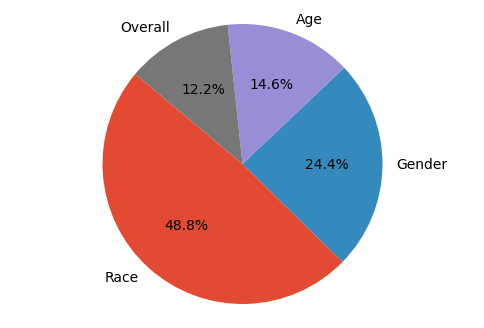

In [142]:
# Plotting pie chart of break_out_category
plt.figure(figsize=(6, 4))
plt.pie(value_count_Break_Out_Category['count'], labels=value_count_Break_Out_Category['Break_Out_Category'], autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.show()

<Axes: xlabel='Break_Out', ylabel='count'>

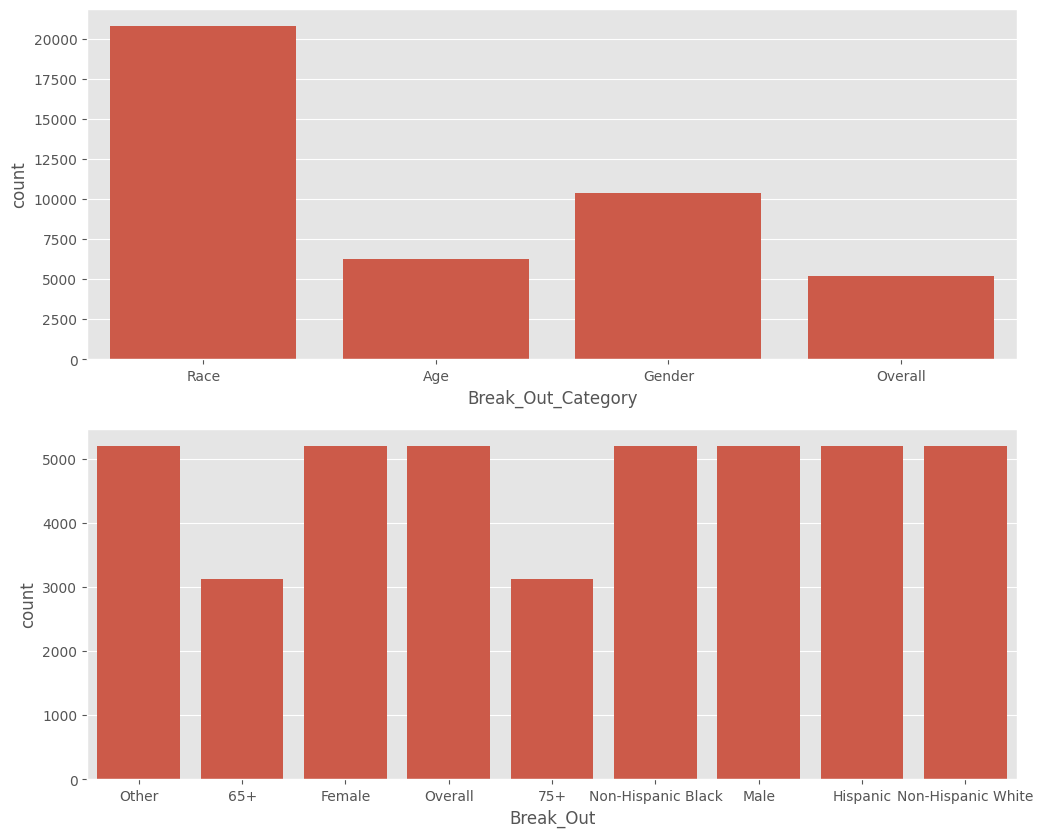

In [143]:
# visualize the distribution of values in the Break_Out_Category and Break_Out columns using count plots. 
fig , axes=plt.subplots(nrows=2, ncols=1,figsize=(12,10))
sb.countplot(data=df, x="Break_Out_Category",ax=axes[0])
sb.countplot(data=df, x="Break_Out",ax=axes[1])

### **Histogram of Topic**
 - The graph indicates that the occurrence of heart failure is significantly higher compared to other categories. Therefore, the data is not balanced.

Text(0.5, 1.0, 'Histogram of Topic')

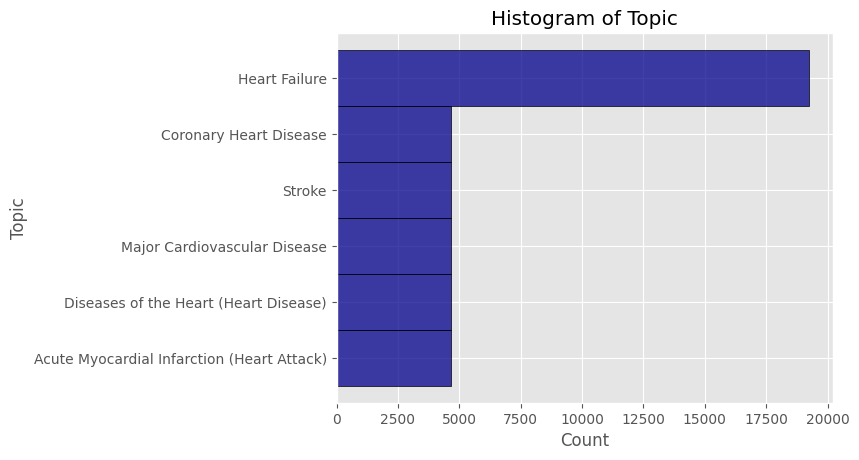

In [144]:
# Histplot of Topic to find out the count
sb.histplot(y="Topic",data=df,color="darkblue",edgecolor='black')
plt.title('Histogram of Topic')

### **Frequency graph of dataset**


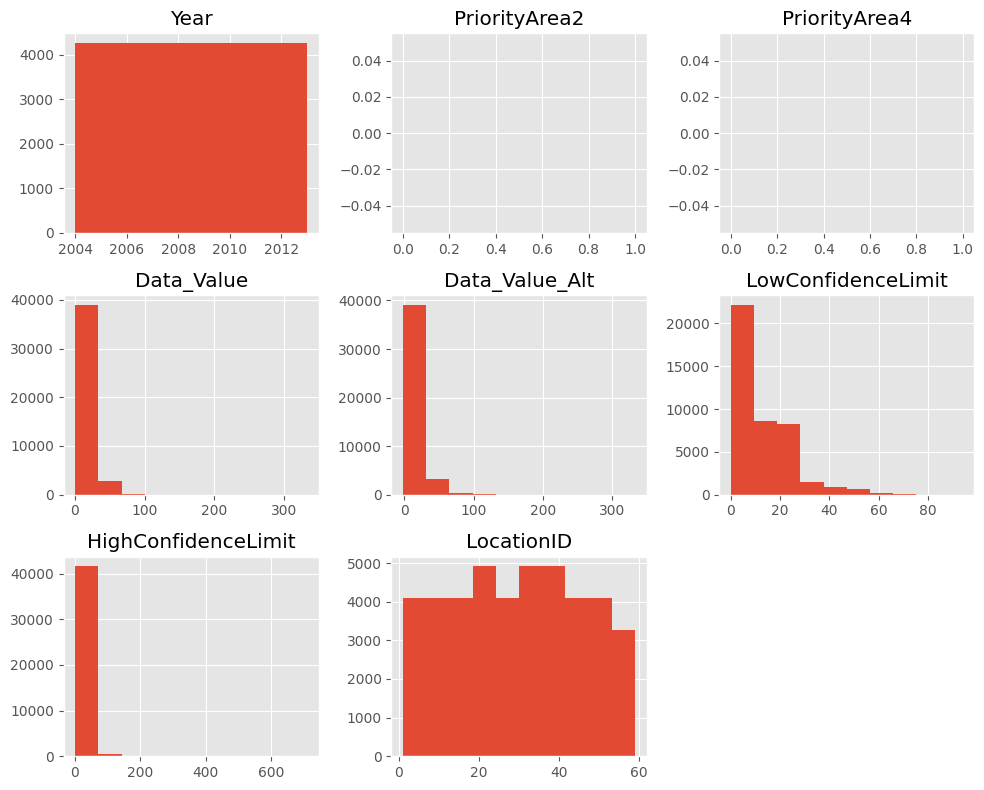

In [145]:
# Frequency graph of dataset
freqgraph=df.select_dtypes(include=['float64','int64'])
freqgraph.hist(figsize=(10,8))
plt.tight_layout()
plt.show()

### **Dealing with Missing Values**
- Most of the columns in the dataset contain missing values. Here, we tried to count the missing values and calculate their percentage relative to the total number of records.

In [146]:
# Looking for  Missing Values
df.isnull()

,Year,LocationAbbr,LocationDesc,DataSource,PriorityArea1,PriorityArea2,PriorityArea3,PriorityArea4,Category,Topic,Indicator,Data_Value_Type,Data_Value_Unit,Data_Value,Data_Value_Alt,Data_Value_Footnote_Symbol,Data_Value_Footnote,LowConfidenceLimit,HighConfidenceLimit,Break_Out_Category,Break_Out,CategoryId,TopicId,IndicatorID,Data_Value_TypeID,BreakOutCategoryId,BreakOutId,LocationID,GeoLocation
0,False,False,False,False,True,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True
1,False,False,False,False,True,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True
2,False,False,False,False,True,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,True,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True
4,False,False,False,False,True,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42635,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False
42636,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False
42637,False,False,False,False,False,True,True,True,False,False,False,False,False,True,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False
42638,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False


In [147]:
df.isnull().sum()


Year                              0
LocationAbbr                      0
LocationDesc                      0
DataSource                        0
PriorityArea1                 33280
PriorityArea2                 42640
PriorityArea3                 28080
PriorityArea4                 42640
Category                          0
Topic                             0
Indicator                         0
Data_Value_Type                   0
Data_Value_Unit                   0
Data_Value                      529
Data_Value_Alt                    0
Data_Value_Footnote_Symbol    42111
Data_Value_Footnote           42111
LowConfidenceLimit              529
HighConfidenceLimit             529
Break_Out_Category                0
Break_Out                         0
CategoryId                        0
TopicId                           0
IndicatorID                       0
Data_Value_TypeID                 0
BreakOutCategoryId                0
BreakOutId                        0
LocationID                  

In [148]:
import missingno as msno


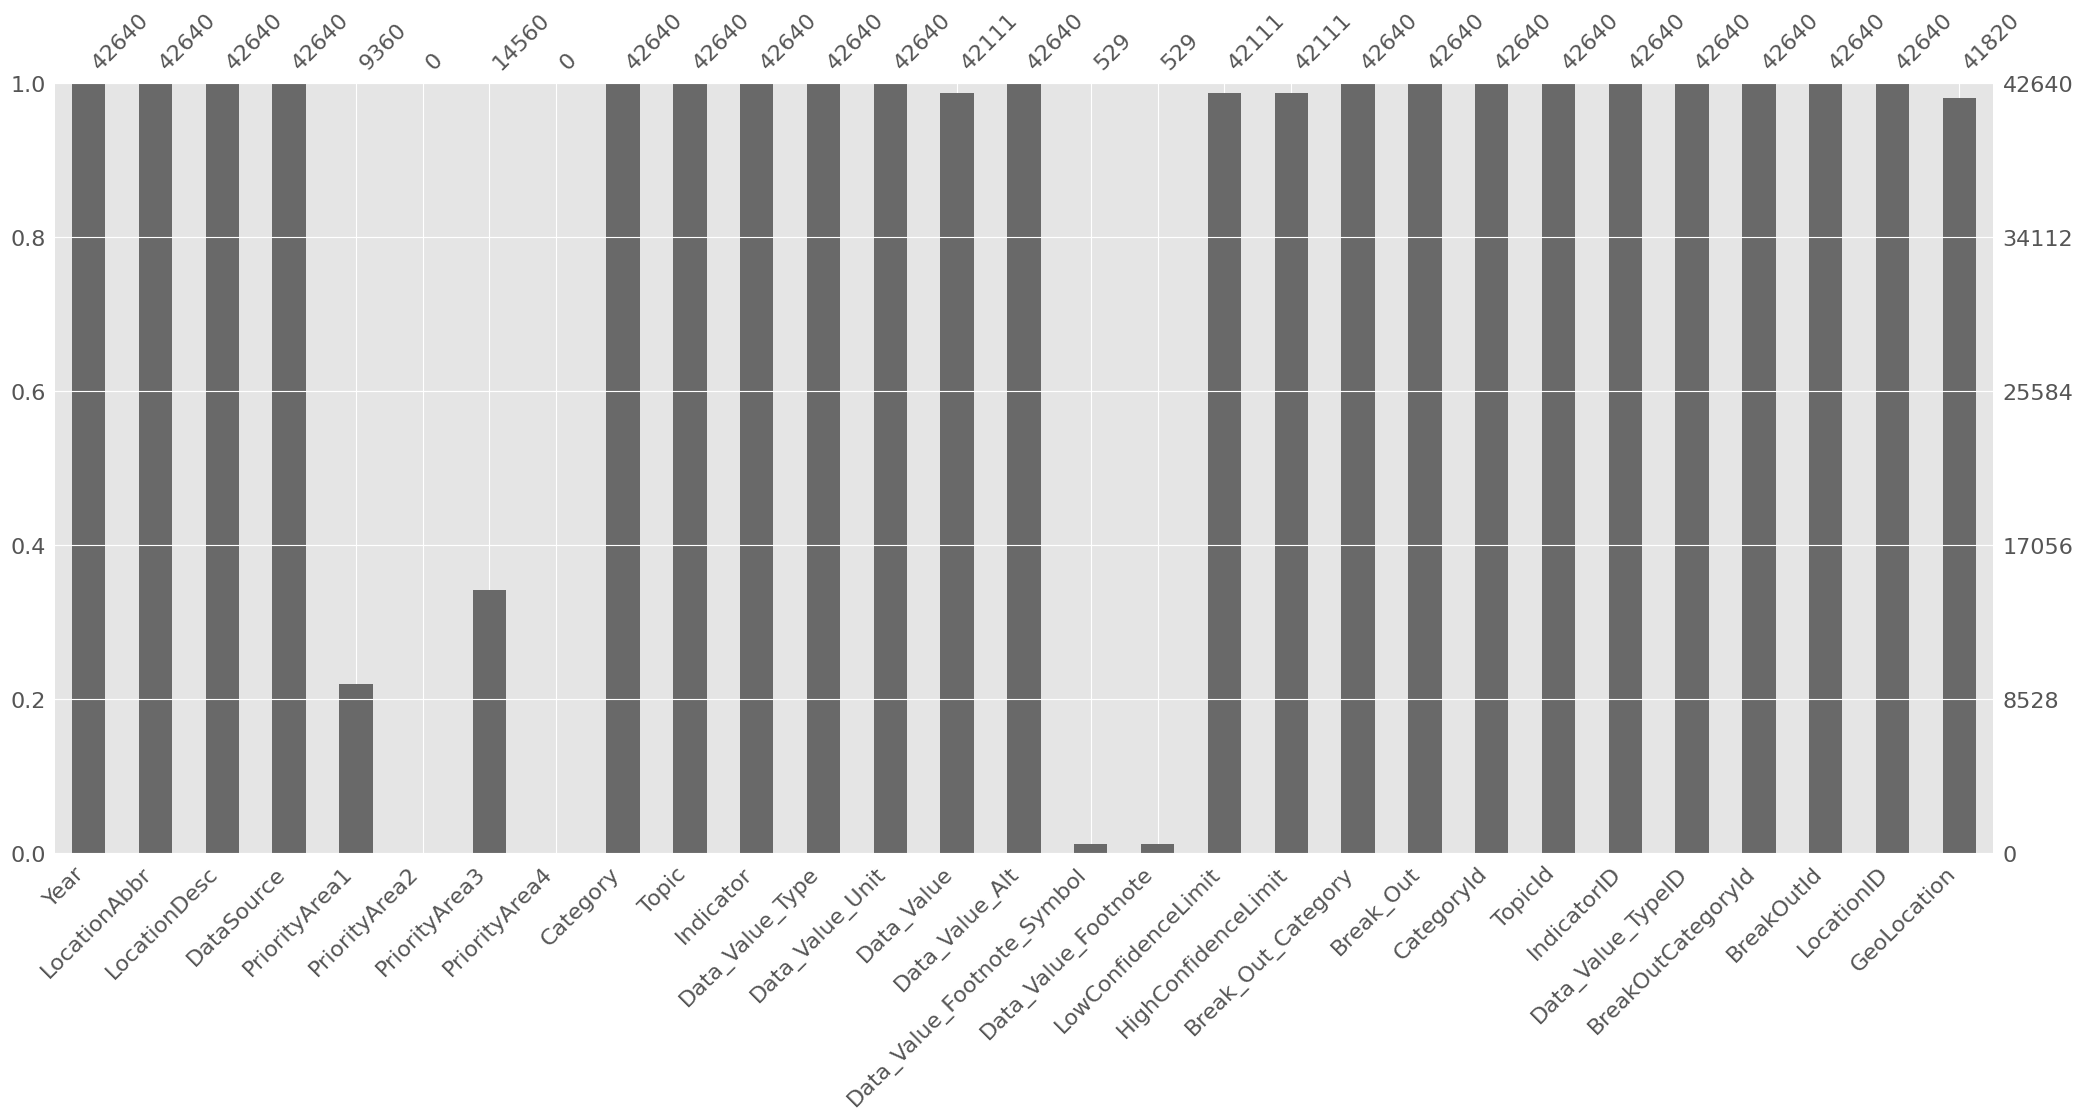

In [149]:
# Visualize the relative missigness of columns
msno.bar(df)
plt.show()

In [150]:
# Which Columns are missing values and what is the extent of Missigness
df.isnull().sum()/len(df)*100

Year                            0.000000
LocationAbbr                    0.000000
LocationDesc                    0.000000
DataSource                      0.000000
PriorityArea1                  78.048780
PriorityArea2                 100.000000
PriorityArea3                  65.853659
PriorityArea4                 100.000000
Category                        0.000000
Topic                           0.000000
Indicator                       0.000000
Data_Value_Type                 0.000000
Data_Value_Unit                 0.000000
Data_Value                      1.240619
Data_Value_Alt                  0.000000
Data_Value_Footnote_Symbol     98.759381
Data_Value_Footnote            98.759381
LowConfidenceLimit              1.240619
HighConfidenceLimit             1.240619
Break_Out_Category              0.000000
Break_Out                       0.000000
CategoryId                      0.000000
TopicId                         0.000000
IndicatorID                     0.000000
Data_Value_TypeI

#### **Visualize  PriorityArea Columns**
-  visualize the distribution of values in the PriorityAreas  columns using count plots. 


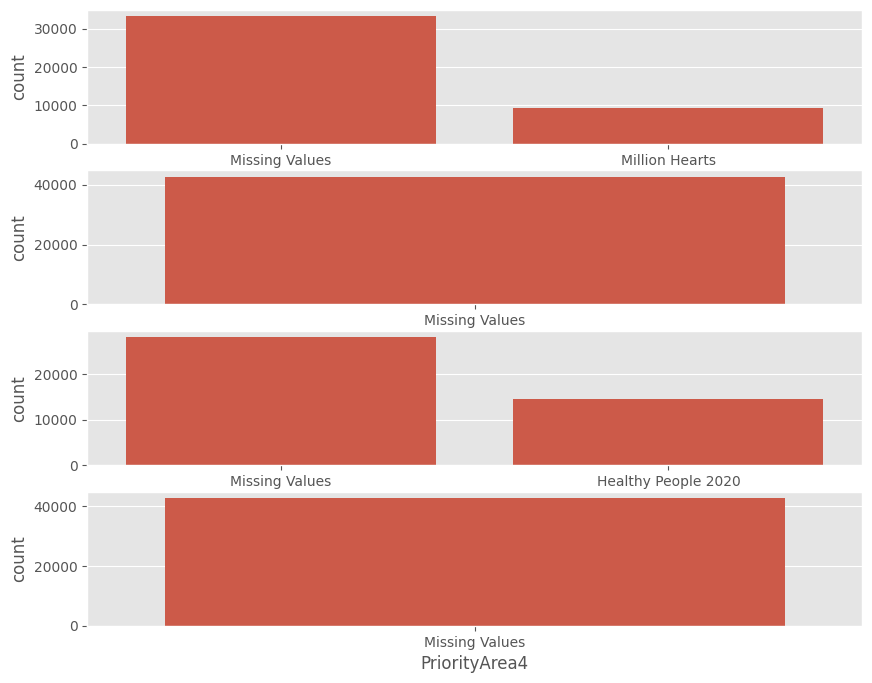

In [151]:
# visualize the distribution of values in the PriorityAreas  columns using count plots. 
fig , axes=plt.subplots(nrows=4 , ncols=1,figsize=(10,8))
df['PriorityArea1'].fillna('Missing Values', inplace=True)
df['PriorityArea2'].fillna('Missing Values', inplace=True)
df['PriorityArea3'].fillna('Missing Values', inplace=True)
df['PriorityArea4'].fillna('Missing Values', inplace=True)
sb.countplot(data=df, x="PriorityArea1",ax=axes[0])
sb.countplot(data=df, x="PriorityArea2",ax=axes[1])
sb.countplot(data=df, x="PriorityArea3",ax=axes[2])
sb.countplot(data=df, x="PriorityArea4",ax=axes[3])
plt.show()


In [152]:
df['PriorityArea1'].replace('Missing Values', None, inplace=True)
df['PriorityArea2'].replace('Missing Values', None, inplace=True)
df['PriorityArea3'].replace('Missing Values', None, inplace=True)
df['PriorityArea4'].replace('Missing Values', None, inplace=True)

#### **Extent of Missigness**

In [153]:
# Which Columns are missing values and what is the extent of Missigness
df.isnull().sum()/len(df)*100

Year                            0.000000
LocationAbbr                    0.000000
LocationDesc                    0.000000
DataSource                      0.000000
PriorityArea1                  78.048780
PriorityArea2                 100.000000
PriorityArea3                  65.853659
PriorityArea4                 100.000000
Category                        0.000000
Topic                           0.000000
Indicator                       0.000000
Data_Value_Type                 0.000000
Data_Value_Unit                 0.000000
Data_Value                      1.240619
Data_Value_Alt                  0.000000
Data_Value_Footnote_Symbol     98.759381
Data_Value_Footnote            98.759381
LowConfidenceLimit              1.240619
HighConfidenceLimit             1.240619
Break_Out_Category              0.000000
Break_Out                       0.000000
CategoryId                      0.000000
TopicId                         0.000000
IndicatorID                     0.000000
Data_Value_TypeI

#### **Dealing with Missing Values**
  - PriorityArea1
  - PriorityArea2
  - PriorityArea3
  - PriorityArea4
  - Data_Value_Footnote_Symbol
  - Data_Value_Footnote
    
  
   columns are missing greater than 65% 

In [154]:
# Drop Columns with missing percentage greater than 65%
# Calculate percentage of missing values in each column
missing_percentage = df.isnull().mean() * 100
# Identify columns with missing percentage greater than or equal to 65%
columns_to_drop = missing_percentage[missing_percentage >= 65].index
# Drop columns from the DataFrame
df= df.drop(columns=columns_to_drop)

In [155]:
df.shape

(42640, 23)

In [156]:
df.isnull().sum()/len(df)*100

Year                   0.000000
LocationAbbr           0.000000
LocationDesc           0.000000
DataSource             0.000000
Category               0.000000
Topic                  0.000000
Indicator              0.000000
Data_Value_Type        0.000000
Data_Value_Unit        0.000000
Data_Value             1.240619
Data_Value_Alt         0.000000
LowConfidenceLimit     1.240619
HighConfidenceLimit    1.240619
Break_Out_Category     0.000000
Break_Out              0.000000
CategoryId             0.000000
TopicId                0.000000
IndicatorID            0.000000
Data_Value_TypeID      0.000000
BreakOutCategoryId     0.000000
BreakOutId             0.000000
LocationID             0.000000
GeoLocation            1.923077
dtype: float64

#### **DataSource,Category and Data value type**
The dataset consistently includes the same data source, category, and data value type. These features are constant and do not vary, so removing them will not affect our predictions

<Axes: xlabel='Data_Value_Type', ylabel='count'>

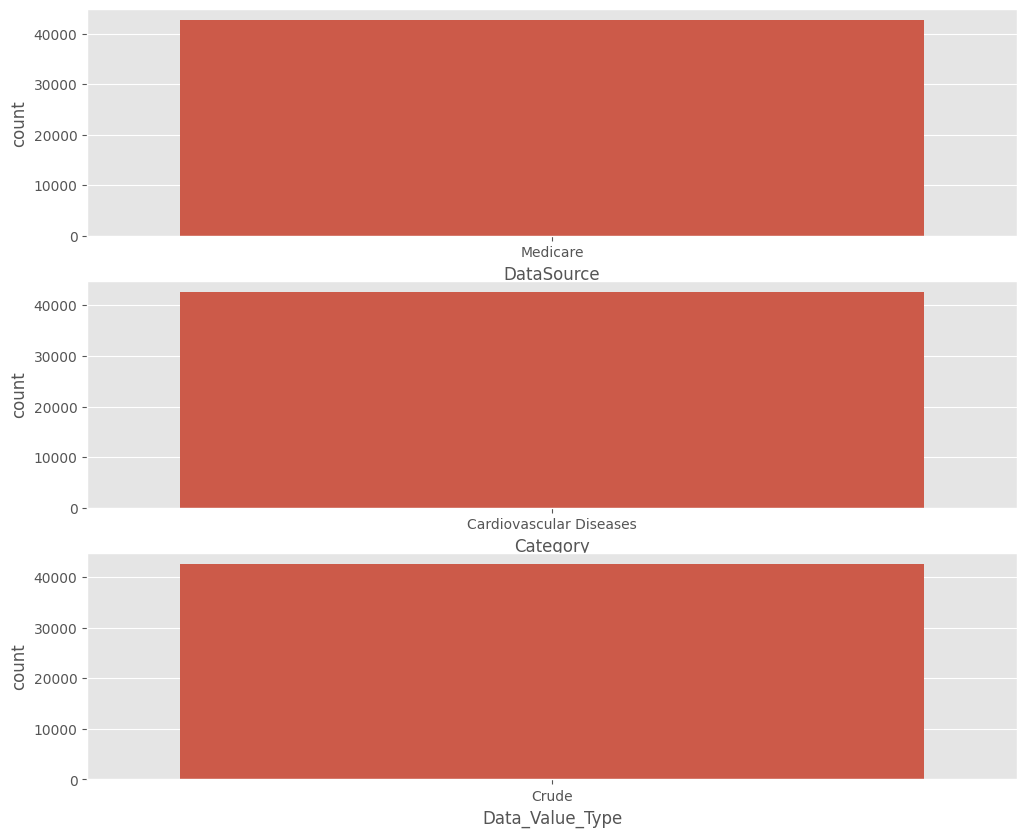

In [157]:
fig , axes=plt.subplots(nrows=3, ncols=1,figsize=(12,10))
sb.countplot(data=df, x="DataSource",ax=axes[0])
sb.countplot(data=df, x="Category",ax=axes[1])
sb.countplot(data=df, x="Data_Value_Type",ax=axes[2])

In [158]:
# Drop Columns that do not vary
df=df.drop(['DataSource'], axis=1)
df=df.drop(['Category'],axis=1)
df=df.drop(['Data_Value_Type'],axis=1)


#### **Removing unnecessary attributes for prediction**
- Geolocation
- Indicator
- LocationAbbr
  We removed both attributes as they are not necessary for prediction.







In [159]:
#Drop GeoLocation as it is unnecessary for prediction
df.drop('GeoLocation', axis = 1,inplace=True)
df.drop('Indicator', axis=1, inplace=True)
df.drop('LocationAbbr', axis = 1,inplace=True)
df.shape

(42640, 17)

#### **Deleting ID Variable not useful for Model**
 From the dataset provided, the ID columns that could potentially be removed are:
- 'CategoryId'                 
- 'TopicId'                    
- 'IndicatorID'                 
- 'Data_Value_TypeID'           
- 'BreakOutCategoryId'          
- 'BreakOutId'                  
- 'LocationID'



In [160]:
df=df.drop(['CategoryId','TopicId','IndicatorID','Data_Value_TypeID','BreakOutCategoryId','BreakOutId','LocationID'], axis=1)

In [161]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42640 entries, 0 to 42639
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 42640 non-null  int64  
 1   LocationDesc         42640 non-null  object 
 2   Topic                42640 non-null  object 
 3   Data_Value_Unit      42640 non-null  object 
 4   Data_Value           42111 non-null  float64
 5   Data_Value_Alt       42640 non-null  float64
 6   LowConfidenceLimit   42111 non-null  float64
 7   HighConfidenceLimit  42111 non-null  float64
 8   Break_Out_Category   42640 non-null  object 
 9   Break_Out            42640 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 3.3+ MB


In [162]:
df.isna().sum()

Year                     0
LocationDesc             0
Topic                    0
Data_Value_Unit          0
Data_Value             529
Data_Value_Alt           0
LowConfidenceLimit     529
HighConfidenceLimit    529
Break_Out_Category       0
Break_Out                0
dtype: int64

#### **Skewness Distribution and Boxplot**

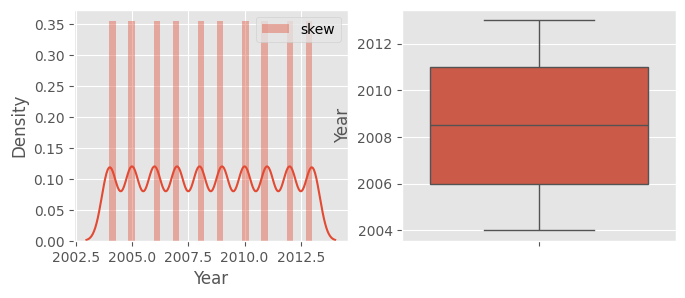

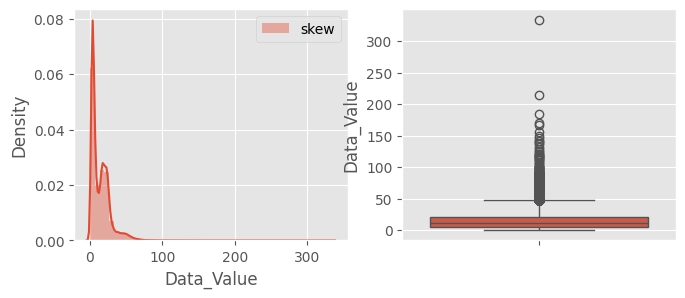

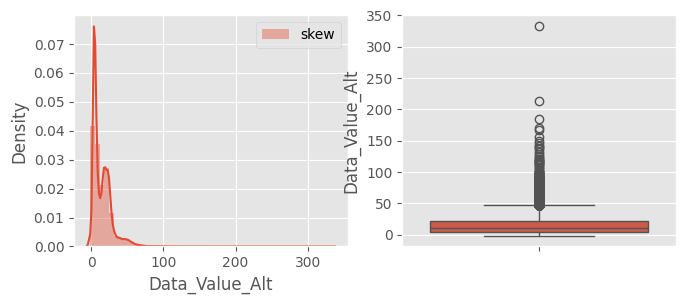

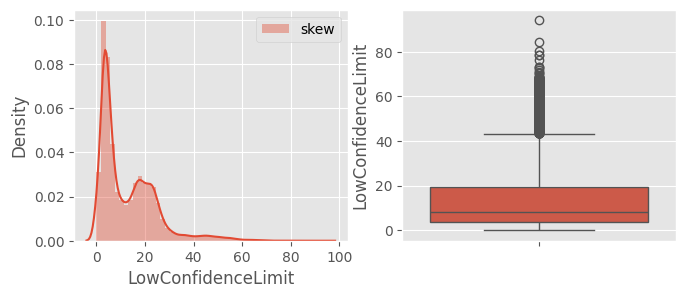

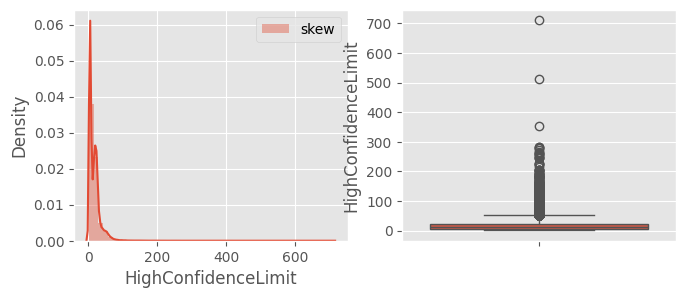

In [163]:
from scipy import stats
for col in df.describe().columns:
  plt.figure(figsize=(12,3))

# Skewness Distribution
  plt.subplot(131)
  sb.distplot(df[col], label="skew" )
  plt.legend()

# Boxplot - For outliers detection
  plt.subplot(132)
  sb.boxplot(df[col])
  plt.show()

#### **Filling the missing For Right-skewed attributes**
- LowConfidenceLimit
- HighConfidenceLimit
  are not normaly distributed they are right-skewed

In [164]:
filler = df["HighConfidenceLimit"].median()
df["HighConfidenceLimit"] = df["HighConfidenceLimit"].fillna(filler)

filler = df["LowConfidenceLimit"].median()
df["LowConfidenceLimit"] = df["LowConfidenceLimit"].fillna(filler)

In [165]:
df.shape
df.duplicated().sum()


176

In [166]:
df.shape
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42640 entries, 0 to 42639
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 42640 non-null  int64  
 1   LocationDesc         42640 non-null  object 
 2   Topic                42640 non-null  object 
 3   Data_Value_Unit      42640 non-null  object 
 4   Data_Value           42111 non-null  float64
 5   Data_Value_Alt       42640 non-null  float64
 6   LowConfidenceLimit   42640 non-null  float64
 7   HighConfidenceLimit  42640 non-null  float64
 8   Break_Out_Category   42640 non-null  object 
 9   Break_Out            42640 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 3.3+ MB


#### **remove duplicate rows with same data but Topic category**

Here, we found a total of 826 rows of records with exactly the same content but assigned different topic categories, which we consider to be inconsistent data.



In [167]:
df['GroupKey'] = df[df.columns.difference(['Topic'])].astype(str).agg('-'.join, axis=1)

# Find rows with the same GroupKey
duplicates = df[df.duplicated('GroupKey', keep=False)]

# Ensure duplicates have different 'Topic' values
duplicates = duplicates.groupby('GroupKey').filter(lambda x: x['Topic'].nunique() > 1)

# Drop the temporary 'GroupKey' column from duplicates
duplicates = duplicates.drop(columns=['GroupKey'])
duplicates.shape

# Drop the rows with the same GroupKey from the original DataFrame
df = df[~df.index.isin(duplicates.index)]

# Drop the temporary 'GroupKey' column from the cleaned DataFrame
df = df.drop(columns=['GroupKey'])
df.shape
# duplicates = df.duplicated(subset=['Break_Out', 'Break_Out_Category','Data_Value_Alt','Data_Value', 'Data_Value_Unit', 'HighConfidenceLimit', 'LocationDesc', 'LowConfidenceLimit', 'Year'], keep=False)
# p= duplicates.sum()
# duplicate_rows = df[duplicates]
# duplicate_rows.to_csv('heart_disease_data_Inconsitent.csv', index=False)

# # Print the duplicate rows
# print(duplicate_rows)
# df = df[~duplicates]

(41814, 10)

In [168]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()
df.shape

(41638, 10)

### **Data Transormation**

#### **Separating Categorical Attributes**
 - Data_Value_Unit
 - Break_Out_Category
 - Break_Out
 - LocationDesc
 - Year  
 - Topic
 
 are categorical attributes

In [169]:
for attribute in df.columns:
    if df[attribute].dtype == object:
        df[attribute] = df[attribute].astype('category')
        
        
df['Year'] = df['Year'].astype('category')  

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41638 entries, 0 to 42639
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Year                 41638 non-null  category
 1   LocationDesc         41638 non-null  category
 2   Topic                41638 non-null  category
 3   Data_Value_Unit      41638 non-null  category
 4   Data_Value           41397 non-null  float64 
 5   Data_Value_Alt       41638 non-null  float64 
 6   LowConfidenceLimit   41638 non-null  float64 
 7   HighConfidenceLimit  41638 non-null  float64 
 8   Break_Out_Category   41638 non-null  category
 9   Break_Out            41638 non-null  category
dtypes: category(6), float64(4)
memory usage: 1.8 MB


In [171]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Data_Value,41397.0,14.936609,13.324233,0.4,4.5,11.2,21.8,333.3
Data_Value_Alt,41638.0,14.838580,13.347595,-2.0,4.5,11.0,21.7,333.3
LowConfidenceLimit,41638.0,12.812979,11.435208,0.0,3.8,8.4,19.7,94.2
HighConfidenceLimit,41638.0,17.169614,17.932992,1.1,5.1,12.9,23.4,710.5


In [172]:
df.describe(include='category').T

,count,unique,top,freq
Year,41638,10,2006,4184
LocationDesc,41638,52,Arizona,820
Topic,41638,6,Heart Failure,18872
Data_Value_Unit,41638,2,Percent (%),27254
Break_Out_Category,41638,4,Race,19993
Break_Out,41638,9,Non-Hispanic White,5180


##### **Bar Plots for Categorical Attributes**

In [173]:
df_categorical_attributes = df.select_dtypes(include=['category'])

df_categorical_attributes

,Year,LocationDesc,Topic,Data_Value_Unit,Break_Out_Category,Break_Out
0,2006,United States,Heart Failure,Percent (%),Race,Other
1,2005,United States,Heart Failure,Percent (%),Race,Other
2,2007,United States,Coronary Heart Disease,Percent (%),Age,65+
3,2008,United States,Coronary Heart Disease,Percent (%),Gender,Female
4,2004,United States,Heart Failure,Percent (%),Overall,Overall
...,...,...,...,...,...,...
42634,2010,Oklahoma,Stroke,Percent (%),Race,Other
42635,2012,Colorado,Stroke,Percent (%),Gender,Male
42636,2010,Michigan,Stroke,Percent (%),Gender,Female
42638,2013,Idaho,Stroke,Percent (%),Race,Non-Hispanic White


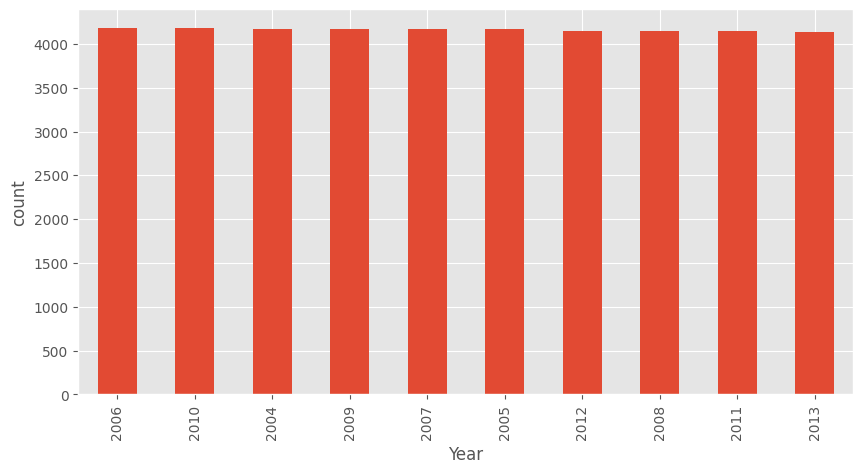

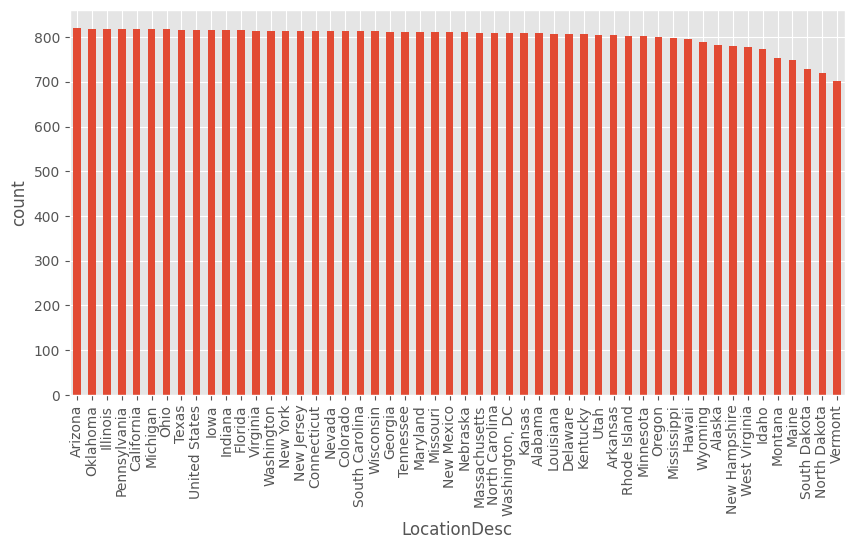

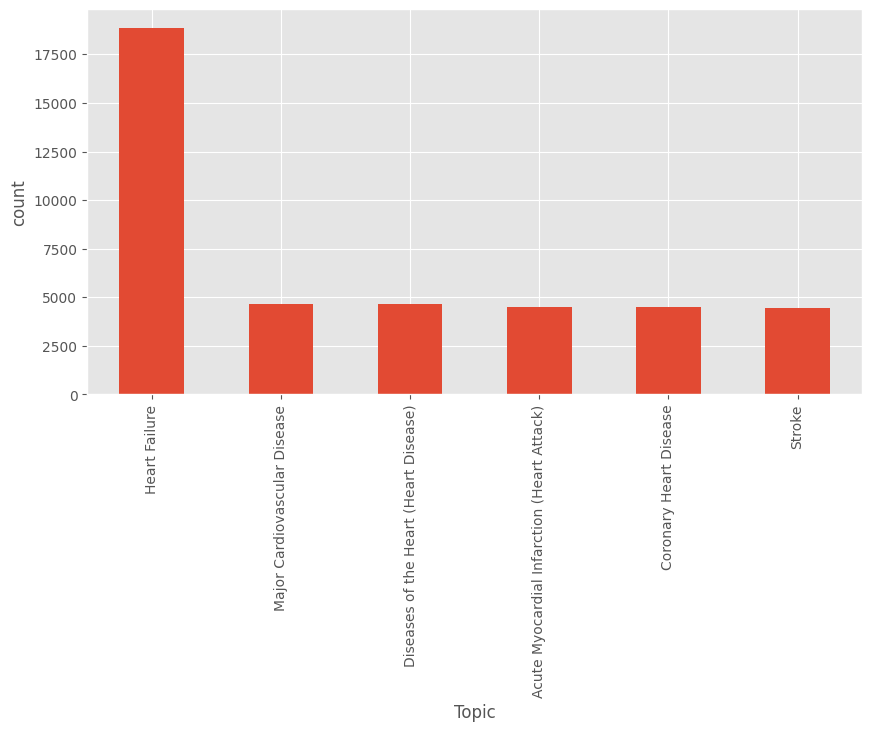

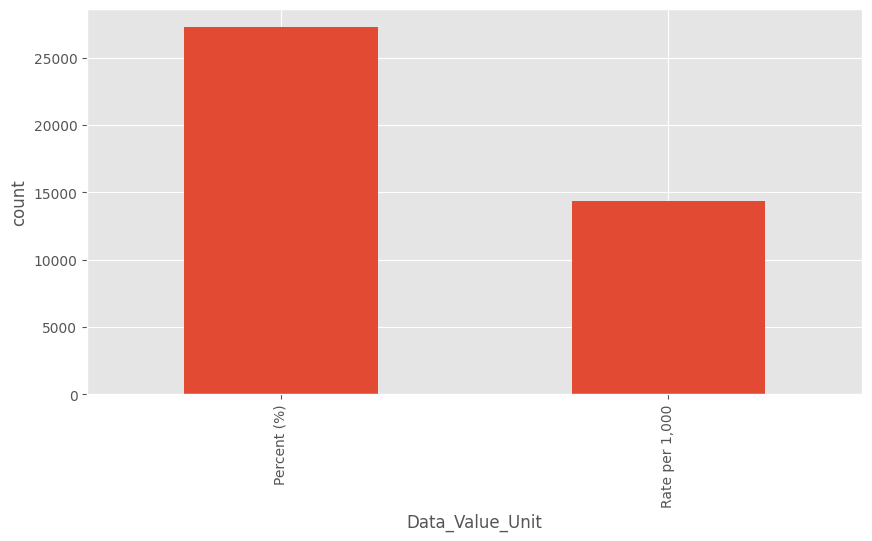

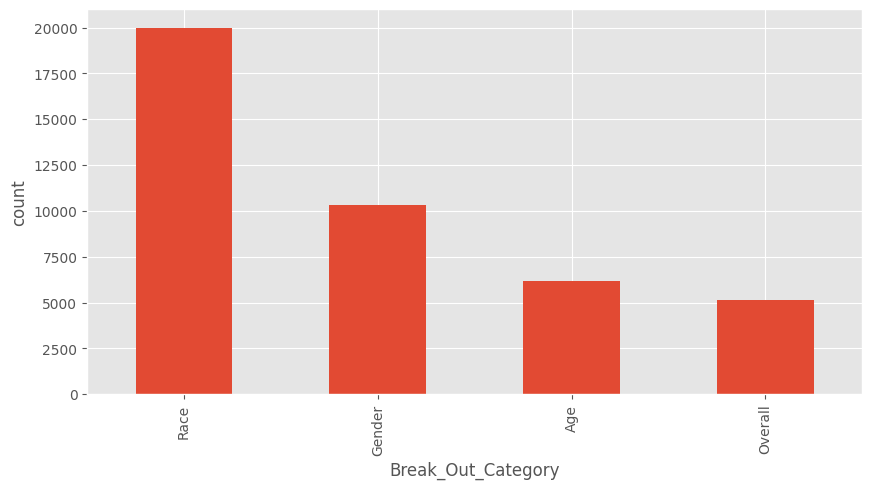

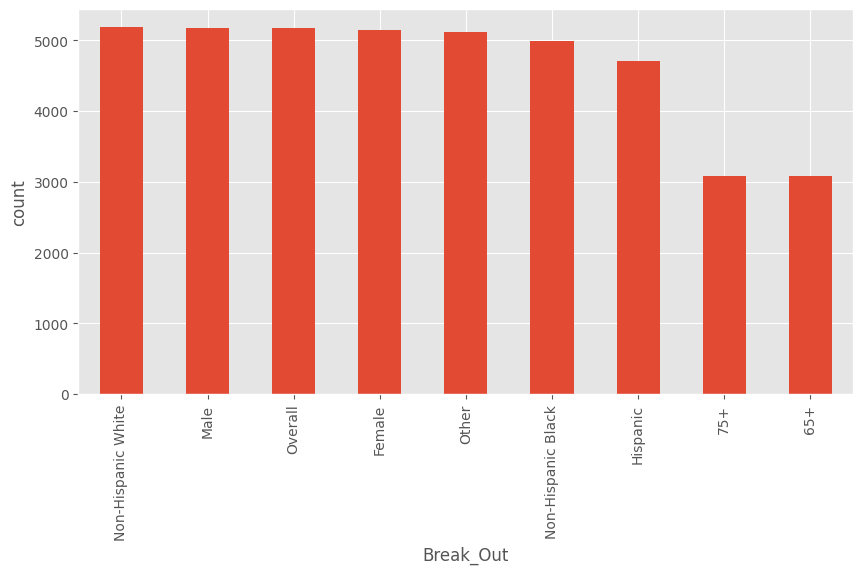

In [174]:
for attribute in df_categorical_attributes:
    val = df[attribute].value_counts()
    val.plot(kind = 'bar', figsize = (10, 5))
    plt.ylabel('count')
    plt.xlabel(attribute)
    plt.show()

#### **Separating Numerical  Attributes**
 - Data_Value
 - Data_Value_ALt
 - LowConfidenceLimit
 - HighConfidenceLimit
 
are Numerical attributes

##### **Building Histogram Numerical  Attributes**


In [175]:
df_numerical_attributes = df.select_dtypes(include=['number'])
df_numerical_attributes


,Data_Value,Data_Value_Alt,LowConfidenceLimit,HighConfidenceLimit
0,5.2,5.2,5.1,5.3
1,5.1,5.1,5.1,5.2
2,8.5,8.5,8.4,8.5
3,5.1,5.1,5.1,5.1
4,6.1,6.1,6.1,6.1
...,...,...,...,...
42634,4.0,4.0,3.7,4.4
42635,3.7,3.7,3.6,3.9
42636,3.4,3.4,3.3,3.5
42638,4.5,4.5,4.3,4.7


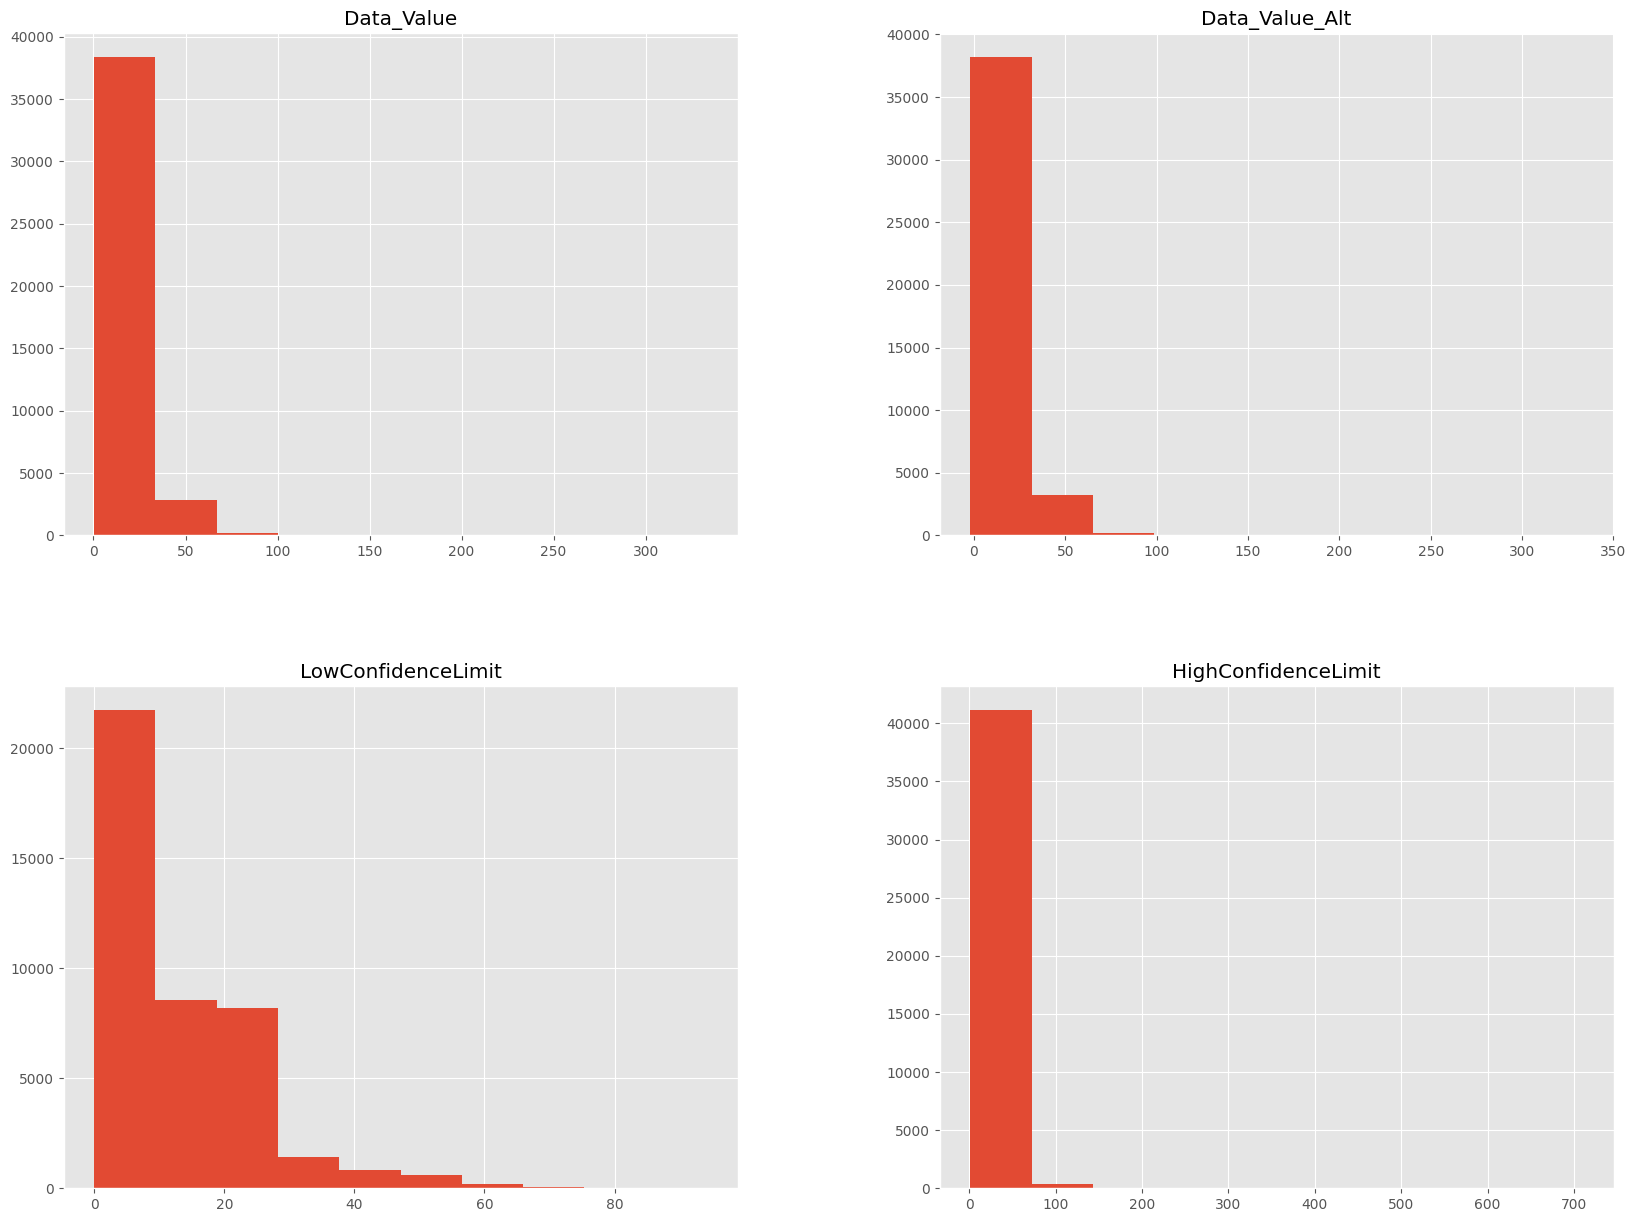

In [176]:
df_numerical_attributes.hist(figsize = (20, 15))
plt.show()

##### **Histograms and bar plots according to the class attributes**


In [177]:
import seaborn as sns

###### **NumericAttributes**

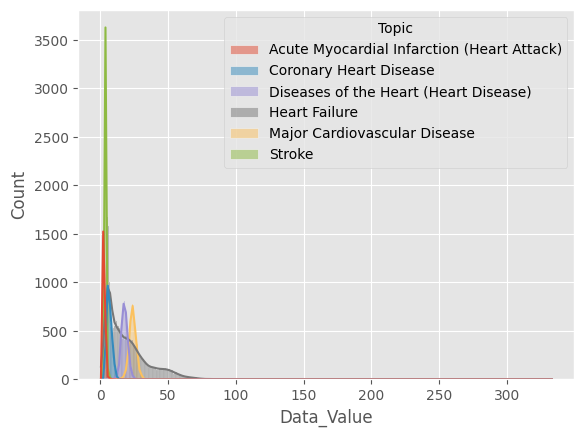

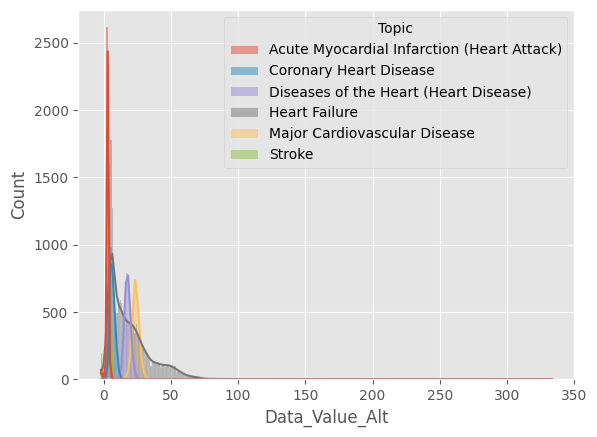

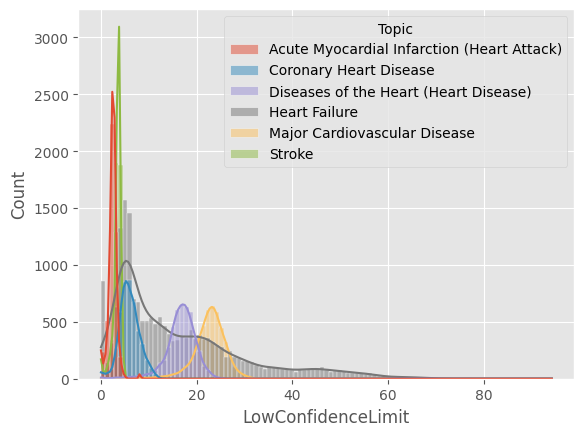

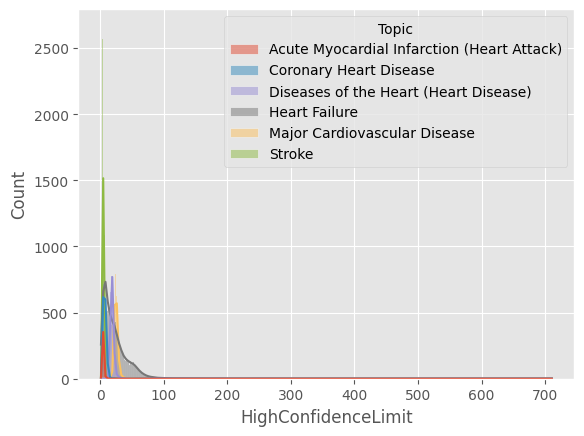

In [178]:
df_numerical_attributesData = df_numerical_attributes.join(df['Topic'])

for attribute in df_numerical_attributes:
    sns.histplot(x = df[attribute], hue = 'Topic', data = df_numerical_attributesData, kde=True)
    plt.show()
    

###### **Bar plots for categorical attributes according to  the class attribute**

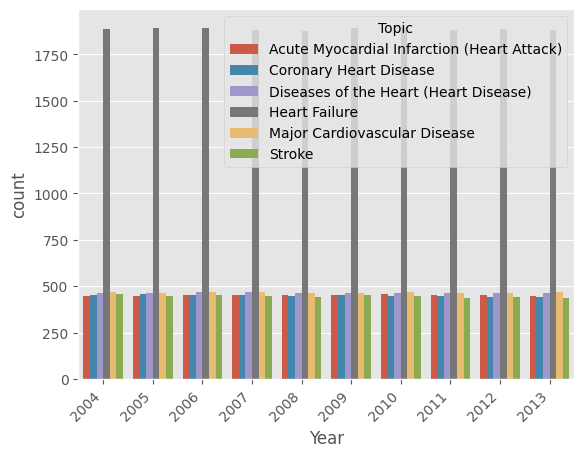

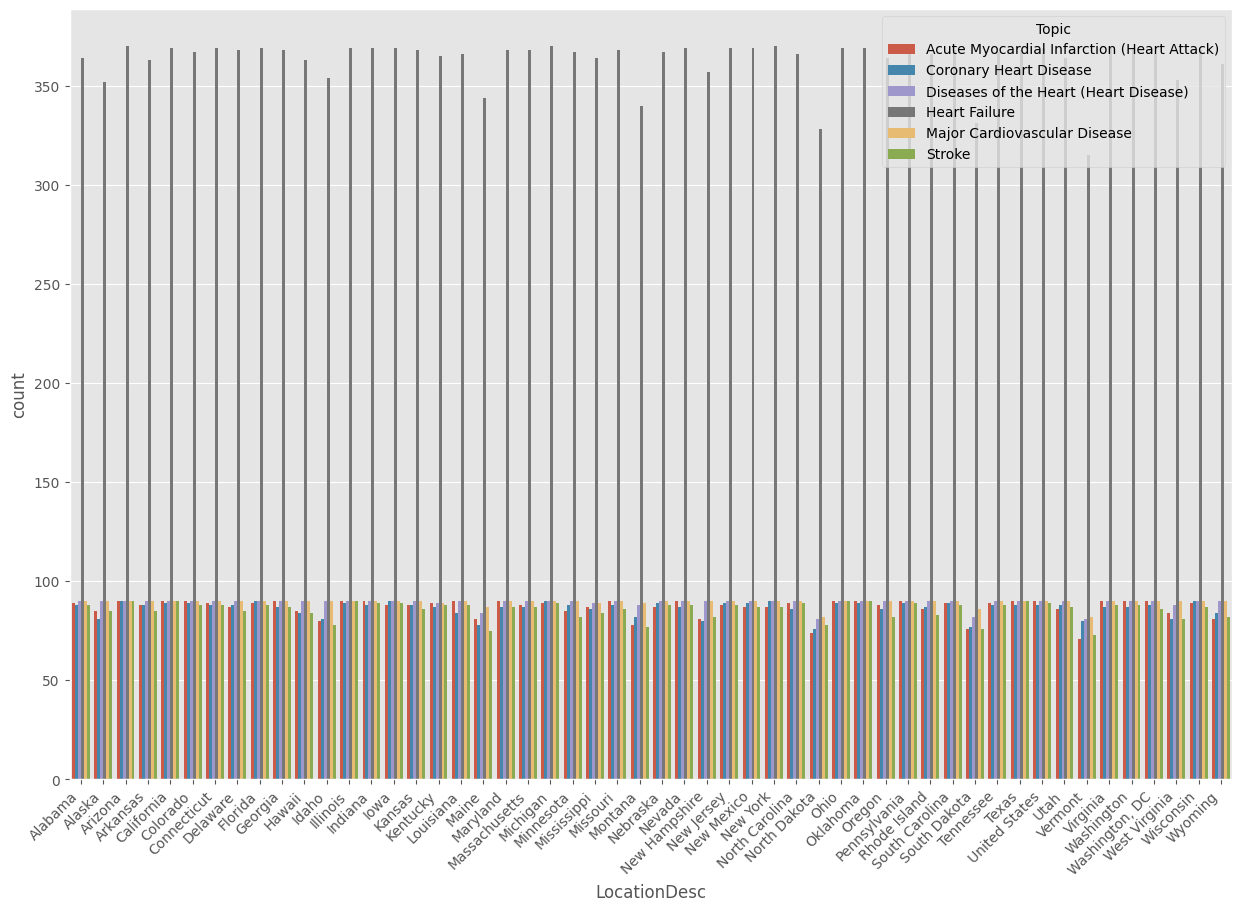

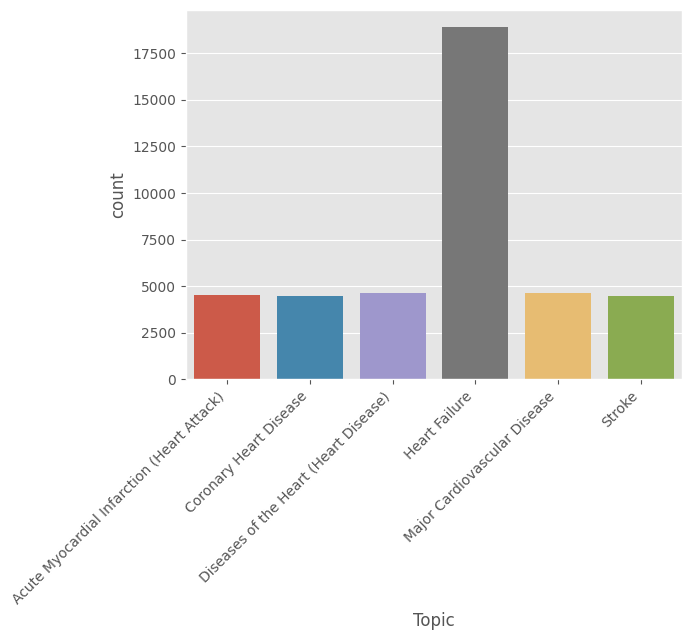

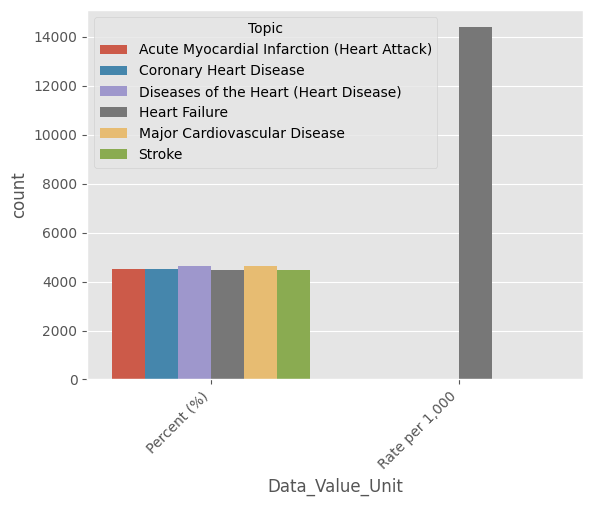

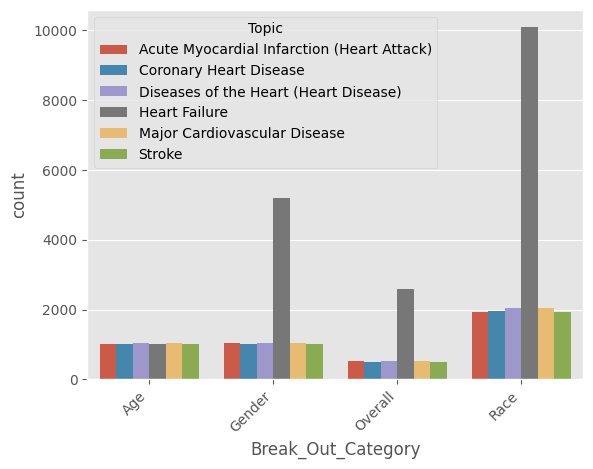

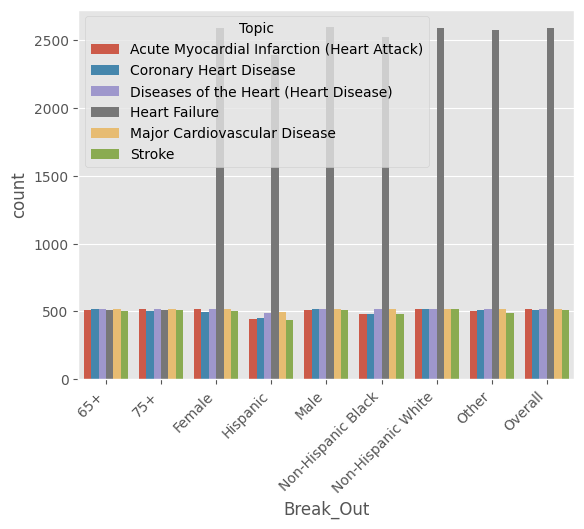

In [179]:
df_categorical_attributesData = df_numerical_attributes.join(df['Topic'])

for attribute in df_categorical_attributes:
    if attribute == 'LocationDesc':
        plt.figure(figsize = (15, 10))
    sns.countplot(x = df[attribute], hue = 'Topic', data = df_categorical_attributesData)
    plt.xticks(rotation=45, ha='right')
    plt.show()

##### **Check Outlier**

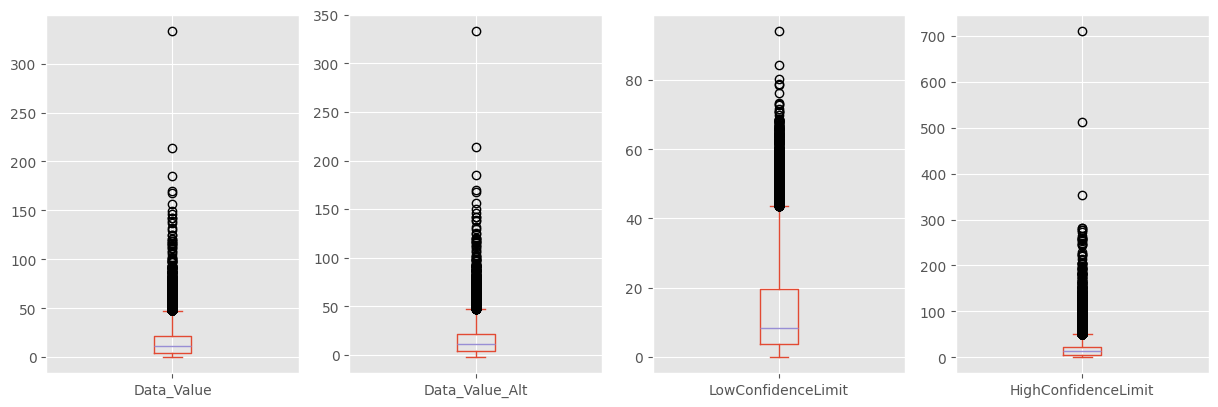

In [180]:
df_numerical_attributes.plot(kind='box', subplots=True, sharex=False, sharey=False, figsize=(15, 27), layout=(5, 4))
plt.show()


In [181]:
df.describe()


,Data_Value,Data_Value_Alt,LowConfidenceLimit,HighConfidenceLimit
count,41397.000000,41638.000000,41638.000000,41638.000000
mean,14.936609,14.838580,12.812979,17.169614
std,13.324233,13.347595,11.435208,17.932992
min,0.400000,-2.000000,0.000000,1.100000
25%,4.500000,4.500000,3.800000,5.100000
50%,11.200000,11.000000,8.400000,12.900000
75%,21.800000,21.700000,19.700000,23.400000
max,333.300000,333.300000,94.200000,710.500000


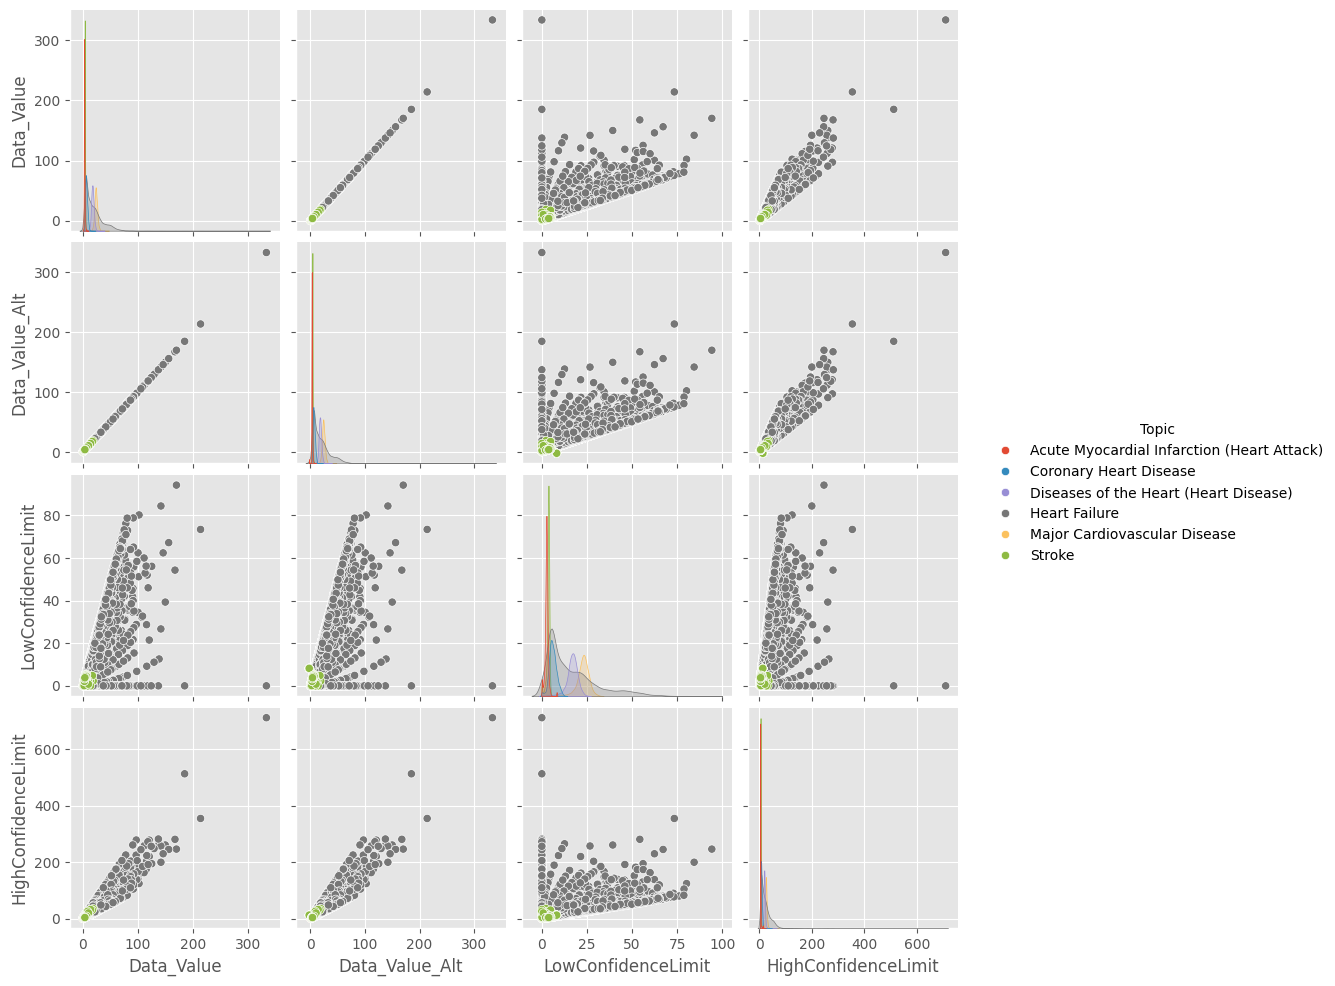

In [182]:
sns.pairplot(df_numerical_attributesData, hue = 'Topic')
plt.show()

#### **Correlation Heatmap**


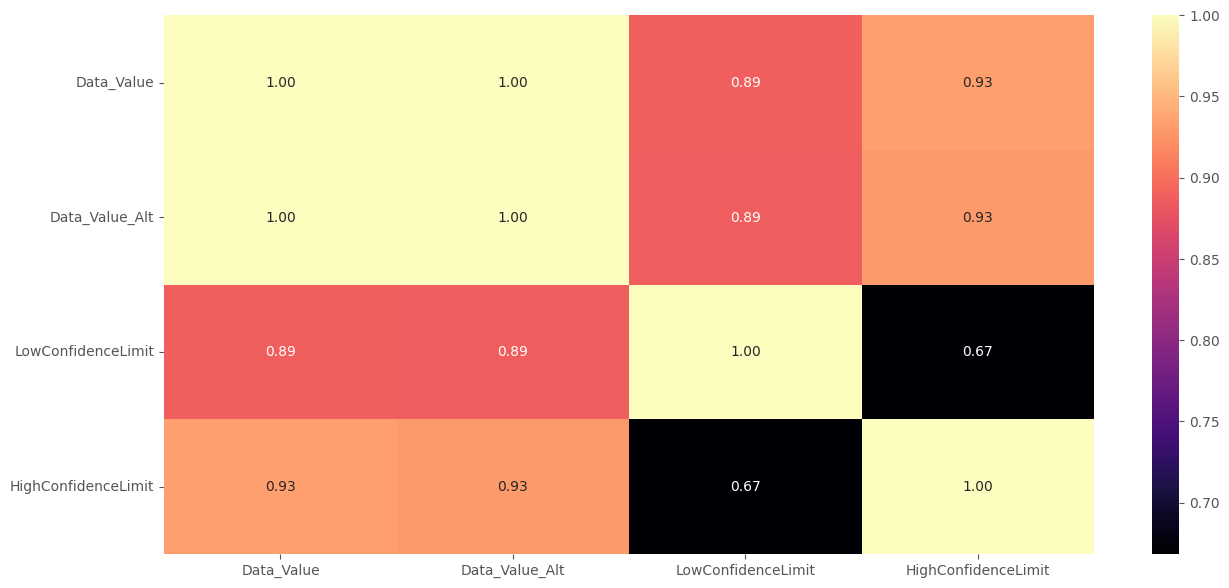

In [184]:
plt.figure(figsize=(15, 7))
sns.heatmap(df_numerical_attributes.corr(), annot=True, cmap='magma', fmt='.2f')
plt.show()


Based on the correlation analysis, it's evident that Data_value and Data_Value_Alt are highly similar Additionally, Data_value shows a strong correlation with both HighConfidenceLimit and LowConfidenceLimit.

##### **Remove Data_Value Attribute**

In [185]:
df=df.drop(['Data_Value'],axis=1)

In [186]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41638 entries, 0 to 42639
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Year                 41638 non-null  category
 1   LocationDesc         41638 non-null  category
 2   Topic                41638 non-null  category
 3   Data_Value_Unit      41638 non-null  category
 4   Data_Value_Alt       41638 non-null  float64 
 5   LowConfidenceLimit   41638 non-null  float64 
 6   HighConfidenceLimit  41638 non-null  float64 
 7   Break_Out_Category   41638 non-null  category
 8   Break_Out            41638 non-null  category
dtypes: category(6), float64(3)
memory usage: 1.5 MB


### **Save our Cleaned Data**

In [187]:
df.to_csv('heart_disease_data_cleaned.csv', index=False)

In [189]:
df.shape

(41638, 9)